In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
df = pd.read_csv("data/load_data.csv")
df.head()

,Date_Time,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,Load_Type
0,01-01-2018 00:15,8.753692,2.95,0.0,0.0,73.210000,100.0,900.000000,Light_Load
1,01-01-2018 00:30,4.000000,4.46,0.0,0.0,66.770000,100.0,1800.000000,Light_Load
2,01-01-2018 00:45,3.240000,3.28,0.0,0.0,70.280000,100.0,8070.880991,Light_Load
3,01-01-2018 01:00,3.310000,3.56,0.0,0.0,68.090000,100.0,3600.000000,Light_Load
4,01-01-2018 01:15,3.820000,4.50,0.0,0.0,133.655666,NaN,4500.000000,Light_Load


In [3]:
print(df.shape)
df.info()

(35041, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35041 entries, 0 to 35040
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Date_Time                             35041 non-null  object 
 1   Usage_kWh                             33482 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  34165 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  33885 non-null  float64
 4   CO2(tCO2)                             34586 non-null  float64
 5   Lagging_Current_Power_Factor          34691 non-null  float64
 6   Leading_Current_Power_Factor          33570 non-null  float64
 7   NSM                                   34586 non-null  float64
 8   Load_Type                             35041 non-null  object 
dtypes: float64(7), object(2)
memory usage: 2.4+ MB


In [4]:
df.isna().sum()

Date_Time                                  0
Usage_kWh                               1559
Lagging_Current_Reactive.Power_kVarh     876
Leading_Current_Reactive_Power_kVarh    1156
CO2(tCO2)                                455
Lagging_Current_Power_Factor             350
Leading_Current_Power_Factor            1471
NSM                                      455
Load_Type                                  0
dtype: int64

In [5]:
df["Load_Type"].value_counts()

Load_Type
Light_Load      18073
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64

In [6]:
df["Date_Time"] = pd.to_datetime(df["Date_Time"], format="%d-%m-%Y %H:%M")
df.dtypes

Date_Time                               datetime64[ns]
Usage_kWh                                      float64
Lagging_Current_Reactive.Power_kVarh           float64
Leading_Current_Reactive_Power_kVarh           float64
CO2(tCO2)                                      float64
Lagging_Current_Power_Factor                   float64
Leading_Current_Power_Factor                   float64
NSM                                            float64
Load_Type                                       object
dtype: object

In [7]:
df = df.rename(columns={
    "Lagging_Current_Reactive.Power_kVarh": "Lagging_Reactive_Power_kVarh",
    "Leading_Current_Reactive_Power_kVarh": "Leading_Reactive_Power_kVarh",
    "CO2(tCO2)": "CO2",
    "Lagging_Current_Power_Factor": "Lagging_PF",
    "Leading_Current_Power_Factor": "Leading_PF",
})
df.columns

Index(['Date_Time', 'Usage_kWh', 'Lagging_Reactive_Power_kVarh',
       'Leading_Reactive_Power_kVarh', 'CO2', 'Lagging_PF', 'Leading_PF',
       'NSM', 'Load_Type'],
      dtype='object')

In [8]:
print("Duplicates:", df.duplicated(subset="Date_Time").sum())
df = df.drop_duplicates(subset="Date_Time").sort_values("Date_Time").reset_index(drop=True)
print(df.shape)

Duplicates: 1
(35040, 9)


In [9]:
print(df["Date_Time"].min(), "to", df["Date_Time"].max())

2018-01-01 00:00:00 to 2018-12-31 23:45:00


In [10]:
train = df[df["Date_Time"] < "2018-12-01"].copy()
test  = df[df["Date_Time"] >= "2018-12-01"].copy()

print("Train:", train.shape, train["Date_Time"].min(), "→", train["Date_Time"].max())
print("Test: ", test.shape,  test["Date_Time"].min(),  "→", test["Date_Time"].max())

Train: (32064, 9) 2018-01-01 00:00:00 → 2018-11-30 23:45:00
Test:  (2976, 9) 2018-12-01 00:00:00 → 2018-12-31 23:45:00


In [11]:
print(train["Load_Type"].value_counts(normalize=True).round(3))
print(test["Load_Type"].value_counts(normalize=True).round(3))

Load_Type
Light_Load      0.509
Medium_Load     0.280
Maximum_Load    0.210
Name: proportion, dtype: float64
Load_Type
Light_Load      0.586
Medium_Load     0.237
Maximum_Load    0.177
Name: proportion, dtype: float64


In [ ]:
EDA 

In [12]:
train.describe().T

,count,mean,min,25%,50%,75%,max,std
Date_Time,32064,2018-06-16 23:52:30,2018-01-01 00:00:00,2018-03-25 11:56:15,2018-06-16 23:52:30,2018-09-08 11:48:45,2018-11-30 23:45:00,NaN
Usage_kWh,30669.0,31.597652,0.0,3.24,5.51,54.32,435.019069,41.869663
Lagging_Reactive_Power_kVarh,31269.0,15.172283,0.0,2.99,5.33,24.55,262.630718,20.592703
Leading_Reactive_Power_kVarh,31007.0,4.221254,0.0,0.0,0.0,1.682019,78.809,8.944338
CO2,31646.0,0.013341,0.0,0.0,0.0,0.02,0.188166,0.020015
Lagging_PF,31741.0,89.849492,0.0,63.54,89.86,100.0,299.996814,39.745108
Leading_PF,30712.0,95.465285,0.0,99.94,100.0,100.0,299.969494,49.48552
NSM,31660.0,47997.418318,0.0,22500.0,45000.0,68400.0,248821.810465,33995.534776


In [13]:
print("NSM > 86400:", (train["NSM"] > 86400).sum())
print("Lagging_PF > 100:", (train["Lagging_PF"] > 100).sum())
print("Leading_PF > 100:", (train["Leading_PF"] > 100).sum())

# NSM that doesn't match the timestamp
true_nsm = train["Date_Time"].dt.hour * 3600 + train["Date_Time"].dt.minute * 60
print("NSM not matching timestamp:", ((train["NSM"] - true_nsm).abs() > 1).sum())

NSM > 86400: 1623
Lagging_PF > 100: 2922
Leading_PF > 100: 2459
NSM not matching timestamp: 3127


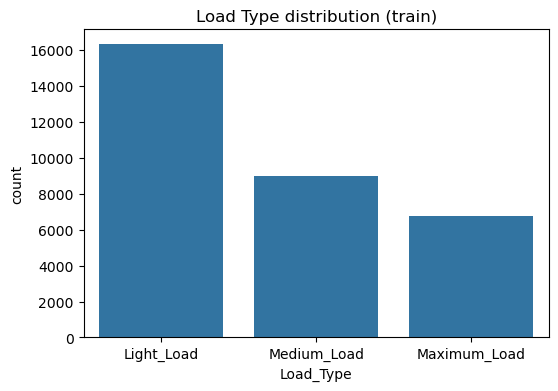

In [14]:
plt.figure(figsize=(6,4))
sns.countplot(data=train, x="Load_Type", order=["Light_Load", "Medium_Load", "Maximum_Load"])
plt.title("Load Type distribution (train)")
plt.show()

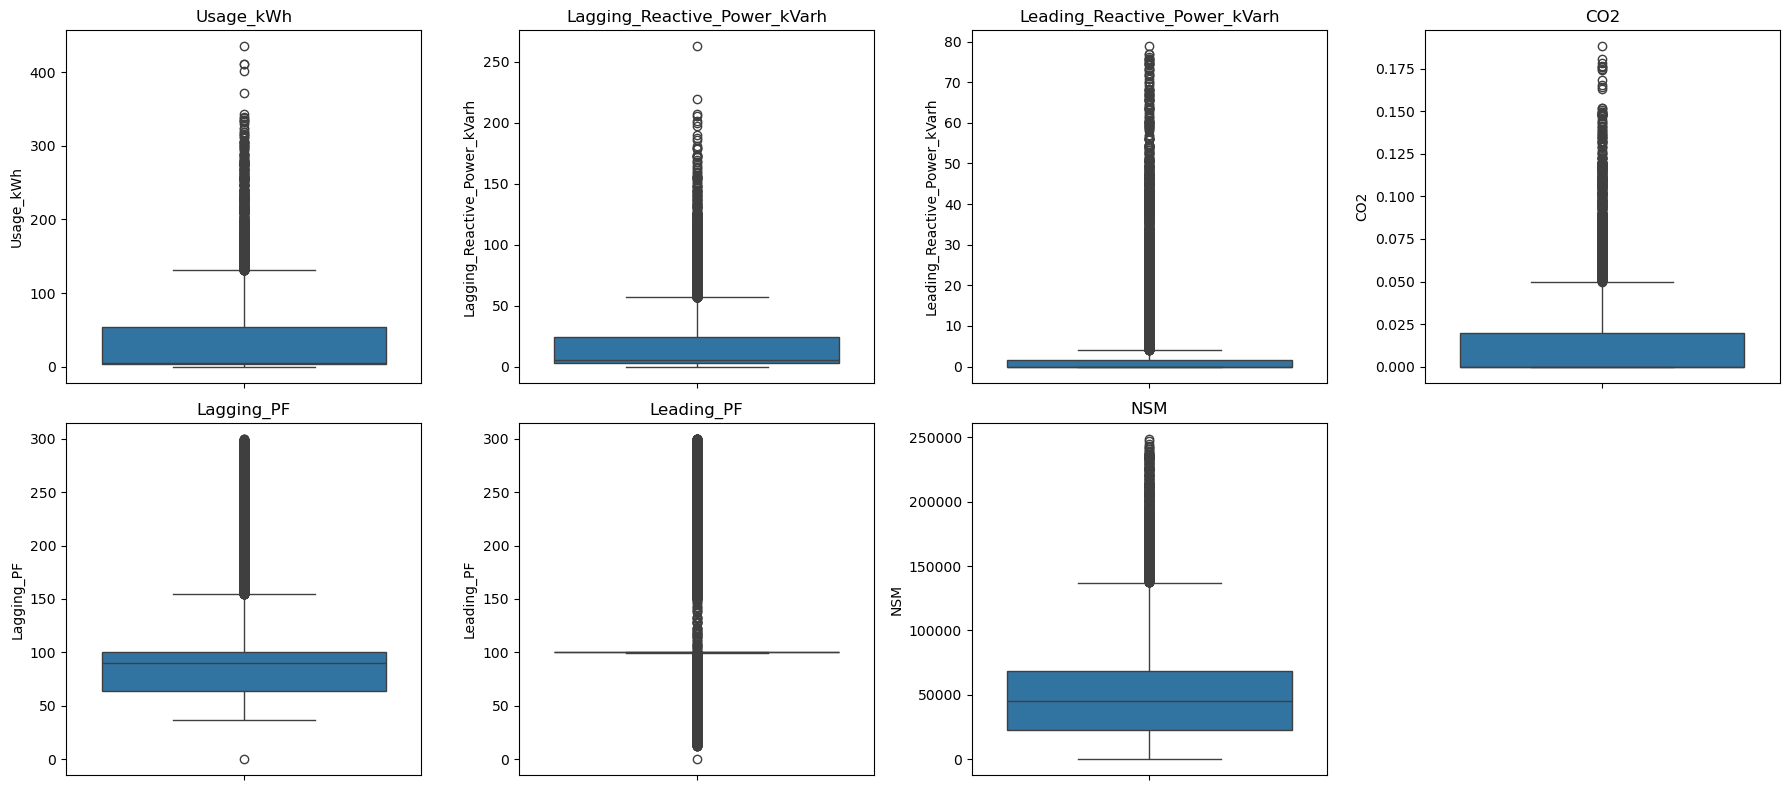

In [15]:
num_cols = ["Usage_kWh", "Lagging_Reactive_Power_kVarh", "Leading_Reactive_Power_kVarh",
            "CO2", "Lagging_PF", "Leading_PF", "NSM"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(y=train[col], ax=ax)
    ax.set_title(col)
axes.flatten()[-1].axis("off")
plt.tight_layout()
plt.show()

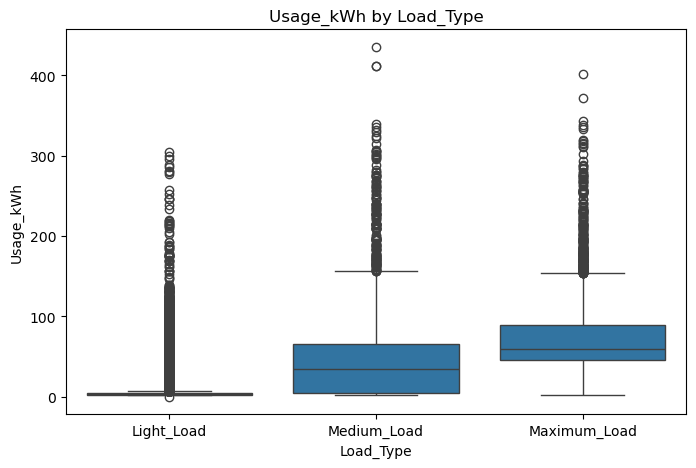

In [16]:
plt.figure(figsize=(8,5))
sns.boxplot(data=train, x="Load_Type", y="Usage_kWh",
            order=["Light_Load", "Medium_Load", "Maximum_Load"])
plt.title("Usage_kWh by Load_Type")
plt.show()

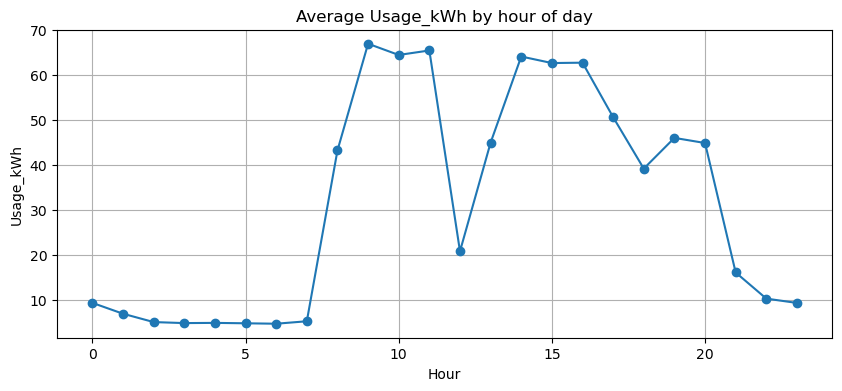

In [17]:
train["hour"] = train["Date_Time"].dt.hour
hourly = train.groupby("hour")["Usage_kWh"].mean()

plt.figure(figsize=(10,4))
hourly.plot(marker="o")
plt.title("Average Usage_kWh by hour of day")
plt.xlabel("Hour"); plt.ylabel("Usage_kWh")
plt.grid(True)
plt.show()

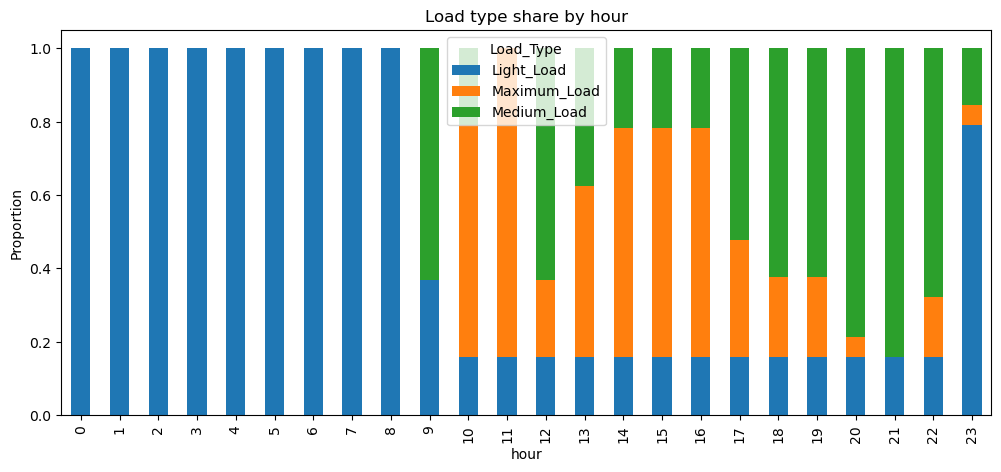

In [18]:
pd.crosstab(train["hour"], train["Load_Type"], normalize="index").plot(
    kind="bar", stacked=True, figsize=(12,5))
plt.title("Load type share by hour")
plt.ylabel("Proportion")
plt.show()

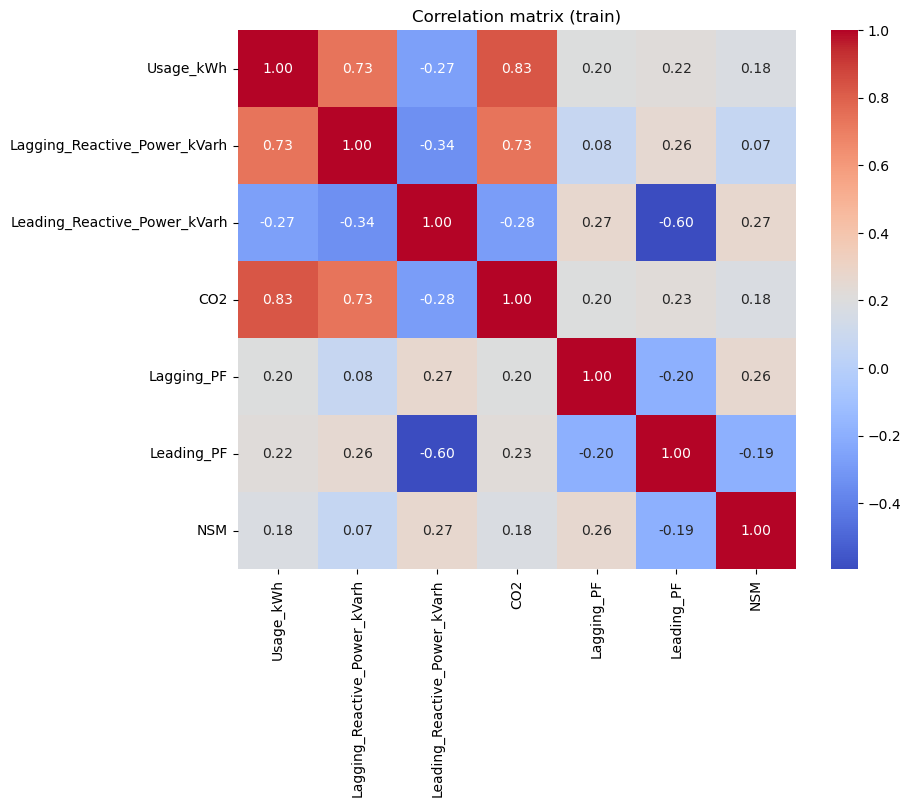

In [19]:
plt.figure(figsize=(9,7))
sns.heatmap(train[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation matrix (train)")
plt.show()

In [ ]:
# Data Cleaning

In [20]:
def fix_invalid(d):
    d = d.copy()
    # recompute NSM from the timestamp
    d["NSM"] = d["Date_Time"].dt.hour * 3600 + d["Date_Time"].dt.minute * 60
    # power factor can't exceed 100, so mark as missing
    for c in ["Lagging_PF", "Leading_PF"]:
        d.loc[d[c] > 100, c] = np.nan
    return d

train = fix_invalid(train)
test  = fix_invalid(test)

In [21]:
cap_cols = ["Usage_kWh", "Lagging_Reactive_Power_kVarh", "Leading_Reactive_Power_kVarh", "CO2"]
caps = train[cap_cols].quantile(0.995)   # limits learned from train only
print(caps)

for c in cap_cols:
    train[c] = train[c].clip(upper=caps[c])
    test[c]  = test[c].clip(upper=caps[c])

Usage_kWh                       226.397552
Lagging_Reactive_Power_kVarh    111.665550
Leading_Reactive_Power_kVarh     47.543755
CO2                               0.105885
Name: 0.995, dtype: float64


In [22]:
fill_cols = cap_cols + ["Lagging_PF", "Leading_PF"]
medians = train[fill_cols].median()      # fallback, from train only

for d in (train, test):
    d[fill_cols] = d[fill_cols].interpolate(method="linear", limit_direction="forward")
    d[fill_cols] = d[fill_cols].fillna(medians)

In [23]:
print(train[fill_cols + ["NSM"]].isna().sum().sum(), test[fill_cols + ["NSM"]].isna().sum().sum())
train.describe().T[["min", "max"]]

0 0


,min,max
Date_Time,2018-01-01 00:00:00,2018-11-30 23:45:00
Usage_kWh,0.0,226.397552
Lagging_Reactive_Power_kVarh,0.0,111.66555
Leading_Reactive_Power_kVarh,0.0,47.543755
CO2,0.0,0.105885
Lagging_PF,0.0,100.0
Leading_PF,0.0,100.0
NSM,0.0,85500.0
hour,0.0,23.0


In [ ]:
# Feature Engineering

In [24]:
full = pd.concat([train, test]).sort_values("Date_Time").reset_index(drop=True)

In [25]:
full["hour"] = full["Date_Time"].dt.hour
full["dayofweek"] = full["Date_Time"].dt.dayofweek
full["is_weekend"] = (full["dayofweek"] >= 5).astype(int)

# cyclic encoding so 23:45 and 00:00 are treated as close together
full["time_sin"] = np.sin(2 * np.pi * full["NSM"] / 86400)
full["time_cos"] = np.cos(2 * np.pi * full["NSM"] / 86400)

In [26]:
full["Total_Reactive"] = full["Lagging_Reactive_Power_kVarh"] + full["Leading_Reactive_Power_kVarh"]
full["Lag_Lead_Ratio"] = full["Lagging_Reactive_Power_kVarh"] / (full["Leading_Reactive_Power_kVarh"] + 1)

In [27]:
full["Usage_lag1"]  = full["Usage_kWh"].shift(1)                       # 15 min ago
full["Usage_lag4"]  = full["Usage_kWh"].shift(4)                       # 1 hour ago
full["Usage_roll4"] = full["Usage_kWh"].shift(1).rolling(4).mean()     # mean of previous hour

lag_cols = ["Usage_lag1", "Usage_lag4", "Usage_roll4"]
full[lag_cols] = full[lag_cols].bfill()    # only the first few rows of January are empty

In [28]:
train = full[full["Date_Time"] < "2018-12-01"].copy()
test  = full[full["Date_Time"] >= "2018-12-01"].copy()
print(train.shape, test.shape)

(32064, 19) (2976, 19)


In [29]:
features = ["Usage_kWh", "Lagging_Reactive_Power_kVarh", "Leading_Reactive_Power_kVarh",
            "CO2", "Lagging_PF", "Leading_PF", "NSM",
            "hour", "dayofweek", "is_weekend", "time_sin", "time_cos",
            "Total_Reactive", "Lag_Lead_Ratio",
            "Usage_lag1", "Usage_lag4", "Usage_roll4"]

label_map = {"Light_Load": 0, "Medium_Load": 1, "Maximum_Load": 2}

X_train, y_train = train[features], train["Load_Type"].map(label_map)
X_test,  y_test  = test[features],  test["Load_Type"].map(label_map)

print(X_train.shape, X_test.shape)
print("Missing:", X_train.isna().sum().sum(), X_test.isna().sum().sum())

(32064, 17) (2976, 17)
Missing: 0 0


In [31]:
%pip install xgboost lightgbm

Note: you may need to restart the kernel to use updated packages.Collecting xgboost
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/48.9 MB ? eta -:--:--
    --------------------------------------- 0.8/48.9 MB 3.0 MB/s eta 0:00:16
   - -------------------------------------- 1.3/48.9 MB 2.7 MB/s eta 0:00:18
   - -------------------------------------- 2.1/48.9 MB 2.9 MB/s eta 0:00:17
   -- ------------------------------------- 2.9/48.9 MB 3.2 MB/s eta 0:00:15
   --- ------------------------------------ 4.2/48.9 MB 3.7 MB/s eta 0:00:13
   ---- ----------------------------------- 5.0/48.9 MB 3.8 MB/s eta 0:00:12
   ---- ----------------------------------- 6.0/48.9 MB 4.0 MB/s eta 0:00:11
   ------ --------------------------------- 7.6/48.9 MB 4.3 MB/s eta 0:00:10
   ------- -------------------------------- 9.2/48.9 MB 4.7 MB/s eta 0:00:09
   -------- -

In [36]:
import os
os.environ["LOKY_MAX_CPU_COUNT"] = "4"   # set to your number of cores

In [32]:
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

In [33]:
models = {
    "Logistic Regression": make_pipeline(StandardScaler(),
                            LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, class_weight="balanced",
                                            n_jobs=-1, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6,
                             eval_metric="mlogloss", random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, class_weight="balanced",
                               random_state=42, verbose=-1),
}

In [37]:
tscv = TimeSeriesSplit(n_splits=5)
scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

rows = []
for name, model in models.items():
    cv = cross_validate(model, X_train, y_train, cv=tscv, scoring=scoring)
    rows.append({
        "Model": name,
        "Accuracy": cv["test_accuracy"].mean(),
        "Precision": cv["test_precision_macro"].mean(),
        "Recall": cv["test_recall_macro"].mean(),
        "F1 (macro)": cv["test_f1_macro"].mean(),
        "F1 std": cv["test_f1_macro"].std(),
    })
    print(f"done: {name}")

cv_results = pd.DataFrame(rows).sort_values("F1 (macro)", ascending=False).round(4)
cv_results

done: Logistic Regression
done: Decision Tree
done: Random Forest
done: XGBoost
done: LightGBM


,Model,Accuracy,Precision,Recall,F1 (macro),F1 std
4,LightGBM,0.8587,0.8284,0.8211,0.8237,0.1221
3,XGBoost,0.8578,0.8281,0.8194,0.8226,0.1220
2,Random Forest,0.8569,0.8287,0.8170,0.8215,0.1219
1,Decision Tree,0.8524,0.8197,0.8183,0.8162,0.1178
0,Logistic Regression,0.8105,0.7759,0.7770,0.7724,0.1016


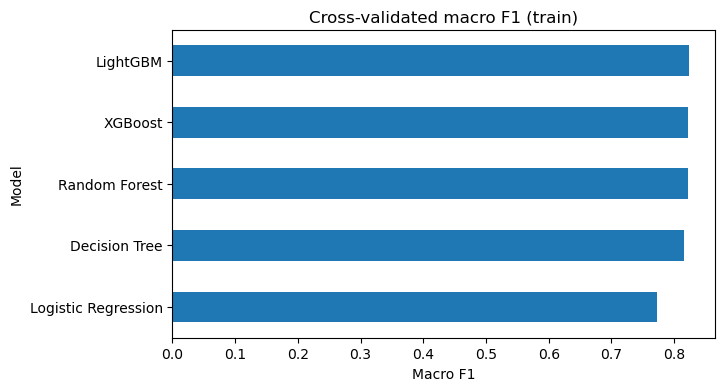

In [38]:
cv_results.set_index("Model")["F1 (macro)"].sort_values().plot(
    kind="barh", figsize=(7,4), title="Cross-validated macro F1 (train)")
plt.xlabel("Macro F1")
plt.show()

In [ ]:
## Hyperparameter Tuning and Final Evaluation

In [39]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(models["LightGBM"], X_train, y_train, cv=tscv, scoring="f1_macro")
print(scores.round(3))

[0.608 0.859 0.932 0.939 0.78 ]


In [40]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators":      [100, 200, 300, 400],
    "learning_rate":     [0.03, 0.05, 0.1],
    "num_leaves":        [15, 31, 63],
    "max_depth":         [-1, 6, 10],
    "min_child_samples": [20, 50, 100],
    "subsample":         [0.7, 0.85, 1.0],
    "colsample_bytree":  [0.7, 0.85, 1.0],
}

search = RandomizedSearchCV(
    LGBMClassifier(class_weight="balanced", subsample_freq=1, random_state=42, verbose=-1),
    param_distributions=param_dist,
    n_iter=15, cv=tscv, scoring="f1_macro",
    random_state=42, n_jobs=-1
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV macro F1:", round(search.best_score_, 4))

Best params: {'subsample': 1.0, 'num_leaves': 31, 'n_estimators': 200, 'min_child_samples': 50, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.85}
Best CV macro F1: 0.8262


In [41]:
best_model = search.best_estimator_      # already refitted on the full training data
y_pred = best_model.predict(X_test)

In [ ]:
## Season effect on Load_Type

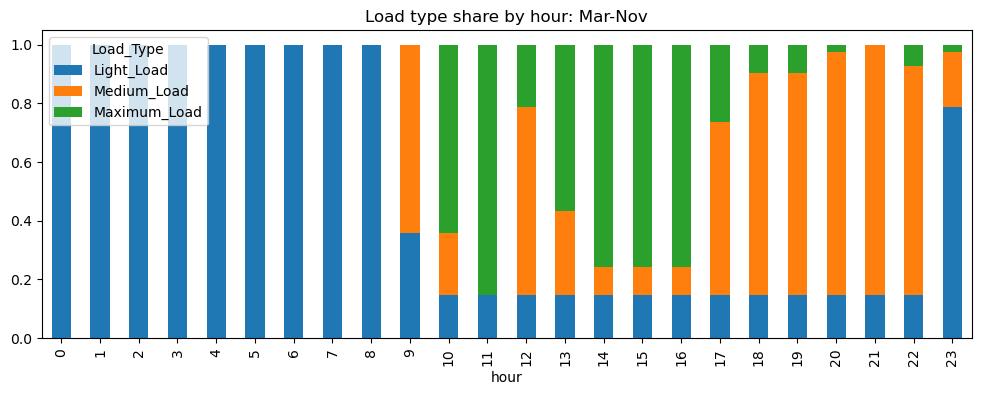

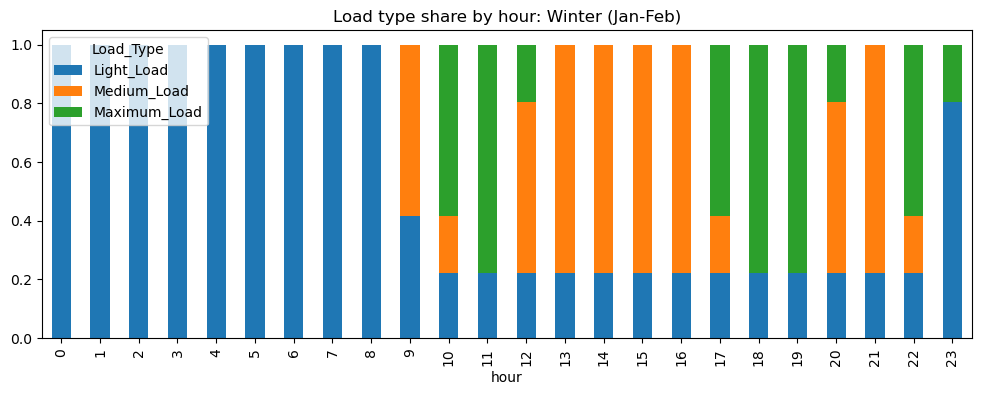

In [45]:
eda = train.copy()
eda["season"] = np.where(eda["Date_Time"].dt.month.isin([1, 2]), "Winter (Jan-Feb)", "Mar-Nov")

for s, g in eda.groupby("season"):
    pd.crosstab(g["hour"], g["Load_Type"], normalize="index")[
        ["Light_Load", "Medium_Load", "Maximum_Load"]
    ].plot(kind="bar", stacked=True, figsize=(12, 4), title=f"Load type share by hour: {s}")
    plt.show()

In [46]:
for d in (train, test):
    d["is_winter"] = d["Date_Time"].dt.month.isin([12, 1, 2]).astype(int)

features = features + ["is_winter"]
X_train, X_test = train[features], test[features]
print(X_train.shape, X_test.shape)

(32064, 18) (2976, 18)


In [47]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators":      [100, 200, 300, 400],
    "learning_rate":     [0.03, 0.05, 0.1],
    "num_leaves":        [15, 31, 63],
    "max_depth":         [-1, 6, 10],
    "min_child_samples": [20, 50, 100],
    "subsample":         [0.7, 0.85, 1.0],
    "colsample_bytree":  [0.7, 0.85, 1.0],
}

search = RandomizedSearchCV(
    LGBMClassifier(class_weight="balanced", subsample_freq=1, random_state=42, verbose=-1),
    param_distributions=param_dist,
    n_iter=15, cv=tscv, scoring="f1_macro",
    random_state=42, n_jobs=-1
)
search.fit(X_train, y_train)

print("Best params:", search.best_params_)
print("Best CV macro F1:", round(search.best_score_, 4))

Best params: {'subsample': 1.0, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 100, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Best CV macro F1: 0.8575


In [48]:
best_model = search.best_estimator_      # already refitted on the full training data
y_pred = best_model.predict(X_test)

In [49]:
from sklearn.metrics import classification_report, accuracy_score, f1_score

names = ["Light_Load", "Medium_Load", "Maximum_Load"]
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print(classification_report(y_test, y_pred, target_names=names, digits=3))

Accuracy: 0.9667
Macro F1: 0.9638
              precision    recall  f1-score   support

  Light_Load      0.954     0.993     0.973      1744
 Medium_Load      0.989     0.903     0.944       704
Maximum_Load      0.985     0.964     0.974       528

    accuracy                          0.967      2976
   macro avg      0.976     0.954     0.964      2976
weighted avg      0.968     0.967     0.966      2976



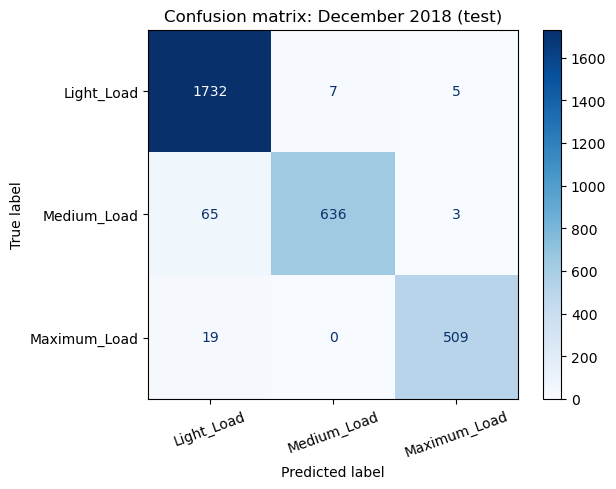

In [50]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=names,
                                        cmap="Blues", xticks_rotation=20)
plt.title("Confusion matrix: December 2018 (test)")
plt.show()

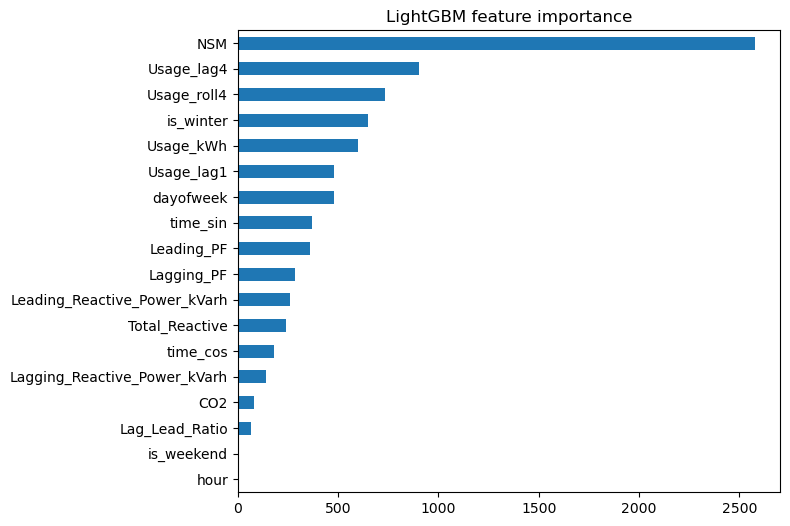

In [51]:
imp = pd.Series(best_model.feature_importances_, index=features).sort_values()
imp.plot(kind="barh", figsize=(7,6), title="LightGBM feature importance")
plt.show()